In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
import os

drive_path = '/content/drive/MyDrive'
item = 'Fruit_ripeness'
source_path = os.path.join(drive_path, item)
destination_path = '/content/Dataset'

if not os.path.exists(destination_path):
    print(f"Copying '{source_path}' to '{destination_path}'...")
    shutil.copytree(source_path, destination_path)
    print("Copy complete.")
else:
    print(f"The directory '{destination_path}' already exists. Skipping copy.")

Copying '/content/drive/MyDrive/Fruit_ripeness' to '/content/Dataset'...
Copy complete.


In [ ]:
import os

dataset_path = '/content/Dataset'

# Kiểm tra xem thư mục có tồn tại không
if not os.path.exists(dataset_path):
    print(f"Lỗi: Thư mục '{dataset_path}' không tồn tại. Vui lòng kiểm tra lại.")
else:
    print(f"Cấu trúc thư mục trong '{dataset_path}':\n")
    for root, dirs, files in os.walk(dataset_path):
        level = root.replace(dataset_path, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f'{indent}{os.path.basename(root)}/')
        subindent = ' ' * 4 * (level + 1)
        # In một vài file mẫu trong mỗi thư mục để có cái nhìn tổng quan
        for i, f in enumerate(files):
            if f.endswith(('.jpg', '.jpeg', '.png')):
                print(f'{subindent}{f}')
            if i >= 2: # Giới hạn 3 file mỗi thư mục để tránh output quá dài
                if len(files) > 3:
                    print(f'{subindent}...')
                break

    print("\nNếu cấu trúc này không như mong đợi hoặc không rõ ràng, vui lòng cung cấp thêm thông tin về cách bạn đã sắp xếp các hình ảnh trái cây và nhãn độ chín (ripe, overripe, unripe) bên trong thư mục 'Dataset'.")

Cấu trúc thư mục trong '/content/Dataset':

Dataset/
    Test/
        Overripe/
            mango_overripe (5).jpg
            banana_overripe (14).jpg
            apple_overripe (99).png
            ...
        Unripe/
            apple_unripe_090.jpg
            orange_unripe (17).jpg
            tomato_unripe_13.jpg
            ...
        Ripe/
            orange_ripe_046.jpeg
            tomato_ripe_21.png
            banana_ripe_054.jpg
            ...
    Valid/
        Overripe/
            mango_overripe (5).jpg
            msg5170347760-69136.jpg
            mango_overripe (14).jpg
            ...
        Unripe/
            orange_unripe (17).jpg
            tomato_unripe_27.jpeg
            banana_unripe_38.jpeg
            ...
        Ripe/
            banana_ripe_5.jpg
            apple_ripe_18.png
            apple_ripe_12.png
            ...
    Train/
        Overipe/
            tomato_overripe (54).png
            orange_overripe (229).jpg
            tomato_overrip

In [ ]:
import os
import shutil
import random

# Đường dẫn đến thư mục dữ liệu gốc
data_dir = '/content/Dataset/'
original_train_dir = os.path.join(data_dir, 'Train')

# Đường dẫn đến các thư mục huấn luyện và xác thực mới
new_train_dir = os.path.join(data_dir, 'Train_Split')
new_val_dir = os.path.join(data_dir, 'Validation_Split')

# Xóa các thư mục cũ nếu chúng tồn tại để tránh lỗi
if os.path.exists(new_train_dir):
    shutil.rmtree(new_train_dir)
if os.path.exists(new_val_dir):
    shutil.rmtree(new_val_dir)

# Tạo các thư mục mới
os.makedirs(new_train_dir, exist_ok=True)
os.makedirs(new_val_dir, exist_ok=True)

print(f"Bắt đầu chia dữ liệu từ '{original_train_dir}'...")

# Lặp qua từng lớp (thư mục con) trong tập huấn luyện gốc
for class_name in os.listdir(original_train_dir):
    class_path = os.path.join(original_train_dir, class_name)
    if os.path.isdir(class_path):
        # Tạo thư mục cho lớp trong các tập mới
        os.makedirs(os.path.join(new_train_dir, class_name), exist_ok=True)
        os.makedirs(os.path.join(new_val_dir, class_name), exist_ok=True)

        # Lấy danh sách tất cả các file ảnh trong lớp
        images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        random.shuffle(images)

        # Chia 80% cho huấn luyện, 20% cho xác thực
        train_split_size = int(0.8 * len(images))
        train_images = images[:train_split_size]
        val_images = images[train_split_size:]

        # Di chuyển các file ảnh vào thư mục mới
        for img in train_images:
            src = os.path.join(class_path, img)
            dst = os.path.join(new_train_dir, class_name, img)
            shutil.copy(src, dst)
        for img in val_images:
            src = os.path.join(class_path, img)
            dst = os.path.join(new_val_dir, class_name, img)
            shutil.copy(src, dst)

        print(f"  Lớp '{class_name}': {len(train_images)} ảnh cho huấn luyện, {len(val_images)} ảnh cho xác thực.")

print("Chia dữ liệu hoàn tất.")

Bắt đầu chia dữ liệu từ '/content/Dataset/Train'...
  Lớp 'Overipe': 1208 ảnh cho huấn luyện, 302 ảnh cho xác thực.
  Lớp 'Unripe': 1200 ảnh cho huấn luyện, 300 ảnh cho xác thực.
  Lớp 'Ripe': 1200 ảnh cho huấn luyện, 300 ảnh cho xác thực.
Chia dữ liệu hoàn tất.


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Định nghĩa các tham số (lấy lại từ cell 61b95803 để đảm bảo tính nhất quán)
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 3
data_dir = '/content/Dataset/'

# Đường dẫn đến các thư mục huấn luyện và xác thực mới đã được chia
new_train_dir = os.path.join(data_dir, 'Train_Split')
new_val_dir = os.path.join(data_dir, 'Validation_Split')

# Tạo ImageDataGenerator cho tập huấn luyện và kiểm tra/xác thực
# Tăng cường dữ liệu cho tập huấn luyện
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Không tăng cường dữ liệu cho tập xác thực và kiểm tra, chỉ chuẩn hóa
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Tải dữ liệu từ thư mục huấn luyện mới
print("Đang tải dữ liệu huấn luyện (đã chia)...")
train_generator = train_datagen.flow_from_directory(
    new_train_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# Tải dữ liệu từ thư mục xác thực mới
print("Đang tải dữ liệu xác thực...")
validation_generator = val_test_datagen.flow_from_directory(
    new_val_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # Không xáo trộn tập xác thực
)

# Tải dữ liệu từ thư mục kiểm tra (không thay đổi)
print("Đang tải dữ liệu kiểm tra (không thay đổi)...")
test_generator = val_test_datagen.flow_from_directory(
    os.path.join(data_dir, 'Test'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # Không xáo trộn tập kiểm tra
)

print("Các Generator đã được thiết lập thành công.")
print(f"Số lớp được phát hiện: {train_generator.num_classes}")
print(f"Các nhãn tương ứng với số thứ tự: {train_generator.class_indices}")

Đang tải dữ liệu huấn luyện (đã chia)...
Found 3608 images belonging to 3 classes.
Đang tải dữ liệu xác thực...
Found 902 images belonging to 3 classes.
Đang tải dữ liệu kiểm tra (không thay đổi)...
Found 709 images belonging to 3 classes.
Các Generator đã được thiết lập thành công.
Số lớp được phát hiện: 3
Các nhãn tương ứng với số thứ tự: {'Overipe': 0, 'Ripe': 1, 'Unripe': 2}


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Khởi tạo mô hình Sequential
model = Sequential([
    # Lớp Conv2D đầu tiên
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)),
    MaxPooling2D((2, 2)),

    # Lớp Conv2D thứ hai
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Lớp Conv2D thứ ba
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Lớp Flatten để chuyển đổi đầu ra từ các lớp tích chập thành vector 1D
    Flatten(),

    # Lớp Dense (Fully Connected) với Dropout để giảm overfitting
    Dense(512, activation='relu'),
    Dropout(0.5),

    # Lớp đầu ra với số lượng neuron bằng số lớp phân loại và hàm kích hoạt softmax
    Dense(NUM_CLASSES, activation='softmax')
])

# Biên dịch mô hình
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Hiển thị tóm tắt mô hình
model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,397,635 (169.36 MB)

 Trainable params: 44,397,635 (169.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# Định nghĩa các tham số huấn luyện
EPOCHS = 50 # Số lượng epoch bạn muốn huấn luyện

# Callback để lưu lại mô hình có độ chính xác tốt nhất trên tập xác thực
checkpoint_filepath = 'best_model.weights.h5'
model_checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True, # Chỉ lưu trọng số của mô hình
    monitor='val_accuracy', # Giám sát độ chính xác trên tập xác thực
    mode='max',
    save_best_only=True
)

# Callback để dừng sớm quá trình huấn luyện nếu độ chính xác không cải thiện
early_stopping_callback = EarlyStopping(
    monitor='val_accuracy',
    patience=10, # Chờ 10 epoch nếu không có cải thiện thì dừng
    mode='max',
    restore_best_weights=True # Khôi phục trọng số của epoch tốt nhất
)

print("Bắt đầu huấn luyện mô hình với tập xác thực riêng biệt...")
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator, # Đã thay đổi từ test_generator sang validation_generator
    callbacks=[model_checkpoint_callback, early_stopping_callback]
)

print("Huấn luyện hoàn tất.")

Bắt đầu huấn luyện mô hình với tập xác thực riêng biệt...
Epoch 1/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 84s 666ms/step - accuracy: 0.6594 - loss: 0.7927 - val_accuracy: 0.6973 - val_loss: 0.5320
Epoch 2/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 62s 552ms/step - accuracy: 0.7736 - loss: 0.4954 - val_accuracy: 0.8004 - val_loss: 0.4189
Epoch 3/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 74s 658ms/step - accuracy: 0.8143 - loss: 0.4248 - val_accuracy: 0.8647 - val_loss: 0.3605
Epoch 4/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 63s 550ms/step - accuracy: 0.8428 - loss: 0.3888 - val_accuracy: 0.8603 - val_loss: 0.3392
Epoch 5/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 68s 607ms/step - accuracy: 0.8426 - loss: 0.3741 - val_accuracy: 0.8703 - val_loss: 0.2789
Epoch 6/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 63s 556ms/step - accuracy: 0.8614 - loss: 0.3332 - val_accuracy: 0.8947 - val_loss: 0.2615
Epoch 7/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 60s 530ms/step - accuracy: 0.8681 - loss: 0.3323 - val_accuracy: 0.8847 - val_loss: 0.2791
Epoch 8/50
113/113 ━━━━━━

In [ ]:
# Load the best weights
model.load_weights(checkpoint_filepath)

# Đánh giá mô hình trên tập kiểm tra
print("Đánh giá mô hình trên tập kiểm tra...")
loss, accuracy = model.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Đánh giá mô hình trên tập kiểm tra...
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 247ms/step - accuracy: 0.8533 - loss: 0.4767
Test Loss: 0.4767
Test Accuracy: 0.8533


In [ ]:
from sklearn.metrics import recall_score
import numpy as np

# Lấy các nhãn thực tế từ test_generator
true_labels = test_generator.classes

# Lấy các dự đoán của mô hình
predictions = model.predict(test_generator)
predicted_labels = np.argmax(predictions, axis=1)

# Tính toán Recall
# Sử dụng 'macro' average để tính toán recall cho mỗi lớp và sau đó lấy trung bình không trọng số.
# Hoặc bạn có thể dùng 'weighted' nếu muốn tính trọng số theo số lượng mẫu của mỗi lớp.
recall = recall_score(true_labels, predicted_labels, average='macro')

print(f"Test Recall (Macro): {recall:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 388ms/step
Test Recall (Macro): 0.8617


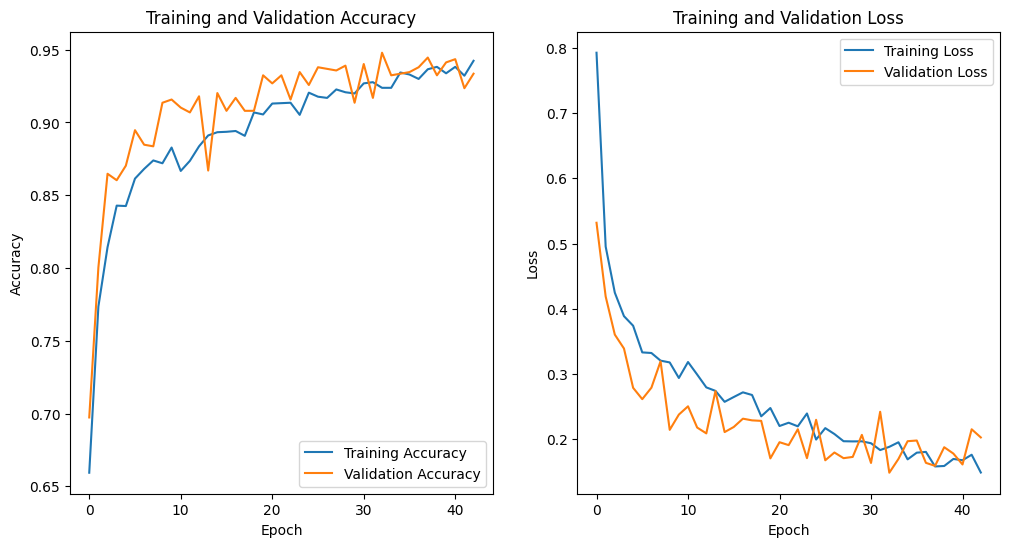

In [ ]:
import matplotlib.pyplot as plt

# Lấy dữ liệu từ lịch sử huấn luyện
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [ ]:
# Lưu toàn bộ mô hình ở định dạng SavedModel
model_save_path = 'fruit_ripeness_model.h5'
model.save(model_save_path)
print(f"Mô hình đã được lưu tại: {model_save_path}")

Mô hình đã được lưu tại: fruit_ripeness_model.h5


In [ ]:
from tensorflow.keras.models import load_model

# Tải lại mô hình
loaded_model = load_model(model_save_path)
print("Mô hình đã được tải lại thành công.")

# Kiểm tra tóm tắt mô hình đã tải lại
loaded_model.summary()

Mô hình đã được tải lại thành công.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,397,637 (169.36 MB)

 Trainable params: 44,397,635 (169.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

### 4.1. Ma trận nhầm lẫn (Confusion Matrix)

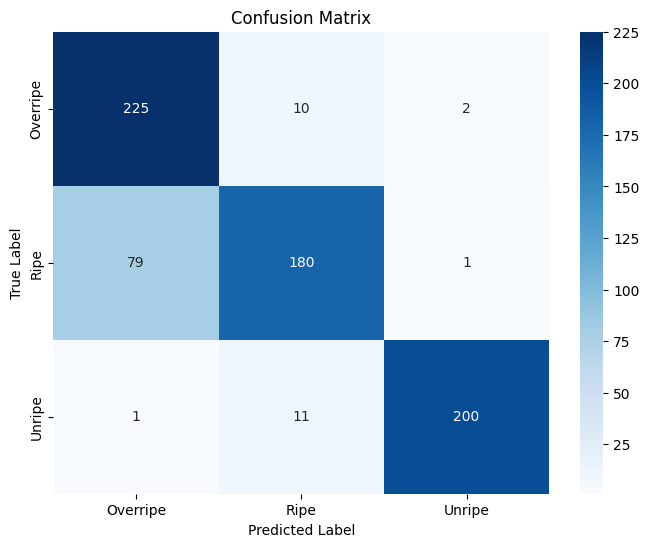

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Lấy các nhãn lớp từ generator để đảm bảo thứ tự khớp
class_names = list(test_generator.class_indices.keys())

# Tạo Confusion Matrix
cm = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

#### Giải thích Ma trận nhầm lẫn:

*   **Hàng (Row):** Đại diện cho các nhãn thực tế (True Labels).
*   **Cột (Column):** Đại diện cho các nhãn được dự đoán (Predicted Labels).
*   **Các giá trị trên đường chéo chính (Diagonal):** Số lượng mẫu được phân loại đúng cho mỗi lớp (True Positives).
*   **Các giá trị ngoài đường chéo chính:** Số lượng mẫu bị phân loại sai, cho biết mô hình đã nhầm lẫn lớp nào với lớp nào. Ví dụ, nếu ô ở hàng 'Unripe' và cột 'Overipe' có giá trị cao, nghĩa là mô hình thường xuyên dự đoán trái cây chưa chín là trái cây quá chín.

### 4.2. Báo cáo phân loại (Classification Report)

In [ ]:
from sklearn.metrics import classification_report

# Lấy các nhãn lớp từ generator để đảm bảo thứ tự khớp
class_names = list(test_generator.class_indices.keys())

# In ra báo cáo phân loại
print(classification_report(true_labels, predicted_labels, target_names=class_names))

              precision    recall  f1-score   support

    Overripe       0.74      0.95      0.83       237
        Ripe       0.90      0.69      0.78       260
      Unripe       0.99      0.94      0.96       212

    accuracy                           0.85       709
   macro avg       0.87      0.86      0.86       709
weighted avg       0.87      0.85      0.85       709



#### Giải thích Báo cáo phân loại:

Báo cáo phân loại cung cấp các chỉ số quan trọng cho từng lớp:

*   **Precision (Độ chính xác):** Tỷ lệ các dự đoán dương tính thực sự đúng trong tất cả các dự đoán dương tính của một lớp. Precision cao nghĩa là khi mô hình dự đoán một mẫu thuộc về lớp đó, khả năng cao là dự đoán đó chính xác.
*   **Recall (Độ thu hồi):** Tỷ lệ các mẫu dương tính thực sự của một lớp được mô hình xác định đúng. Recall cao nghĩa là mô hình có khả năng tìm thấy hầu hết các trường hợp thuộc về lớp đó.
*   **F1-score:** Là trung bình điều hòa của Precision và Recall, cung cấp một cái nhìn tổng thể về độ chính xác của mô hình, đặc biệt hữu ích khi có sự mất cân bằng giữa Precision và Recall.
*   **Support:** Số lượng mẫu thực tế thuộc về mỗi lớp trong tập kiểm tra.

**Macro Avg:** Tính trung bình của Precision, Recall, F1-score cho tất cả các lớp mà không tính đến sự mất cân bằng lớp.
**Weighted Avg:** Tính trung bình có trọng số của Precision, Recall, F1-score cho tất cả các lớp, có tính đến số lượng mẫu của mỗi lớp.

In [ ]:
import os

model_h5_size = os.path.getsize('/content/fruit_ripeness_model.h5') / (1024 * 1024) # Kích thước tính bằng MB
weights_h5_size = os.path.getsize('/content/best_model.weights.h5') / (1024 * 1024) # Kích thước tính bằng MB

print(f"Kích thước file fruit_ripeness_model.h5: {model_h5_size:.2f} MB")
print(f"Kích thước file best_model.weights.h5: {weights_h5_size:.2f} MB")

Kích thước file fruit_ripeness_model.h5: 508.14 MB
Kích thước file best_model.weights.h5: 508.13 MB
